# Speech command classification

This experiment uses local Speech Commands WAV files in `speech_commands/<class>/`. The dataset and pretrained model weights are not included. Training, validation and test partitions are disjoint at the file level. The local filenames do not preserve speaker identifiers, so the split cannot guarantee separation by speaker; scores can overestimate performance on new speakers. The saved results were generated on Kaggle with the corrected split and evaluated on the held-out test files.

**Data:** A local seven-class speech-command WAV collection under `speech_commands/<class>/`. The exact original public source is not confirmed. The exact files used in the saved experiments are not included; provide a compatible seven-class collection to run the notebook.

## Аудио → мел-спектрограмма → преобразование в log-mel и нормализация → positional encoding → audio Transformer (AST), предобученный на AudioSet → классификатор

In [1]:
import os
import torch
import torchaudio
import soundfile as sf
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from transformers import ASTFeatureExtractor, ASTForAudioClassification
from tqdm.auto import tqdm

if torch.cuda.is_available():
    DEVICE = "cuda"  # GPU в Colab (бесплатно доступна T4 или K80)
    print(f"✅ Используется GPU: {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
    DEVICE = "mps"  # Только для Mac с чипом Apple Silicon
    print("✅ Используется MPS (Apple Silicon)")
else:
    DEVICE = "cpu"
    print("⚠️ GPU не найден, используется CPU (будет очень медленно)")

print(f"Итоговое устройство: {DEVICE}")
SAMPLE_RATE = 16000
BATCH_SIZE = 8
EPOCHS = 10
NUM_CLASSES = 7

CLASSES = ['down', 'left', 'off', 'on', 'right', 'stop', 'up']

feature_extractor = ASTFeatureExtractor.from_pretrained(
    "MIT/ast-finetuned-audioset-10-10-0.4593"
)

✅ Используется GPU: Tesla T4
Итоговое устройство: cuda


preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

In [2]:
class SpeechCommandsDataset(Dataset):
    def __init__(self, root_dir, classes):
        self.files = []
        self.labels = []
        self.classes = classes

        for label, cls in enumerate(classes):
            cls_dir = os.path.join(root_dir, cls)
            for fname in sorted(os.listdir(cls_dir)):
                if fname.endswith(".wav"):
                    self.files.append(os.path.join(cls_dir, fname))
                    self.labels.append(label)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        wav_np, sr = sf.read(self.files[idx], dtype="float32")
        waveform = torch.from_numpy(wav_np)

        if waveform.ndim == 1:
            pass
        else:
            waveform = waveform.mean(dim=1)  # to mono

        if sr != SAMPLE_RATE:
            waveform = torchaudio.functional.resample(waveform, sr, SAMPLE_RATE)

        inputs = feature_extractor(
            waveform,
            sampling_rate=SAMPLE_RATE,
            return_tensors="pt"
        )

        return {
            "input_values": inputs["input_values"].squeeze(0),
            "labels": torch.tensor(self.labels[idx])
        }

In [3]:
from sklearn.model_selection import train_test_split
DATA_ROOT = os.environ.get("SPEECH_COMMANDS_ROOT", "speech_commands")
full_dataset = SpeechCommandsDataset(DATA_ROOT, CLASSES)
indices = np.arange(len(full_dataset))
labels = np.asarray(full_dataset.labels)
train_val_idx, test_idx = train_test_split(indices, test_size=0.15, random_state=42, stratify=labels)
train_idx, val_idx = train_test_split(train_val_idx, test_size=0.1765, random_state=42, stratify=labels[train_val_idx])
train_ds = torch.utils.data.Subset(full_dataset, train_idx)
val_ds = torch.utils.data.Subset(full_dataset, val_idx)
test_ds = torch.utils.data.Subset(full_dataset, test_idx)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
print(f"Train: {len(train_ds)}, validation: {len(val_ds)}, test: {len(test_ds)}")

Train: 11529, validation: 2471, test: 2471


In [4]:
model = ASTForAudioClassification.from_pretrained(
    "MIT/ast-finetuned-audioset-10-10-0.4593",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)

model.to(DEVICE)

for param in model.parameters():
    param.requires_grad = False

backbone = model.audio_spectrogram_transformer
# Transformers versions expose encoder blocks under different attributes.
blocks = backbone.layers if hasattr(backbone, "layers") else backbone.encoder.layer
for layer in blocks[-2:]:
    for p in layer.parameters():
        p.requires_grad = True

for p in model.classifier.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

config.json:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `527`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([7, 768])
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([7])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


In [5]:
best_acc = -float("inf")
best_epoch = 0

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch in tqdm(train_loader, desc=f"Train {epoch+1}/{EPOCHS}"):
        optimizer.zero_grad()

        input_values = batch["input_values"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        outputs = model(
            input_values=input_values,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = torch.argmax(outputs.logits, dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= len(train_loader)
    train_acc = train_correct / train_total

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f"Val   {epoch+1}/{EPOCHS}"):
            input_values = batch["input_values"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            outputs = model(
                input_values=input_values,
                labels=labels
            )

            loss = outputs.loss
            val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= len(val_loader)
    val_acc = val_correct / val_total

    print(
        f"[{epoch+1:2d}/{EPOCHS}] "
        f"train loss: {train_loss:.4f}  acc: {train_acc:.4f} | "
        f"val loss: {val_loss:.4f}  acc: {val_acc:.4f}"
    )

    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch + 1
        torch.save(model.state_dict(), "best_ast_speech.pt")
        print(f"→ новая лучшая модель, сохранена (acc = {val_acc:.4f})")

print(f"\nЛучшая валидационная точность: {best_acc:.4f} на эпохе {best_epoch}")

Train 1/10:   0%|          | 0/1442 [00:00<?, ?it/s]

Val   1/10:   0%|          | 0/309 [00:00<?, ?it/s]

[ 1/10] train loss: 0.4309  acc: 0.8479 | val loss: 0.2399  acc: 0.9199


→ новая лучшая модель, сохранена (acc = 0.9199)


Train 2/10:   0%|          | 0/1442 [00:00<?, ?it/s]

Val   2/10:   0%|          | 0/309 [00:00<?, ?it/s]

... (24 outputs left out)

[ 9/10] train loss: 0.0291  acc: 0.9909 | val loss: 0.2576  acc: 0.9385


Train 10/10:   0%|          | 0/1442 [00:00<?, ?it/s]

Val   10/10:   0%|          | 0/309 [00:00<?, ?it/s]

[10/10] train loss: 0.0347  acc: 0.9879 | val loss: 0.2462  acc: 0.9437

Лучшая валидационная точность: 0.9514 на эпохе 8


In [6]:
model.load_state_dict(torch.load("best_ast_speech.pt", map_location=DEVICE, weights_only=True))
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for batch in test_loader:
        input_values = batch["input_values"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        outputs = model(input_values=input_values)
        preds = torch.argmax(outputs.logits, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {acc:.4f}")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASSES,
        zero_division=0,
        digits=4
    )
)

Test accuracy: 0.9563
              precision    recall  f1-score   support

        down     0.9510    0.9887    0.9694       353
        left     0.9577    0.9632    0.9605       353
         off     0.9436    0.9008    0.9217       353
          on     0.9444    0.9632    0.9537       353
       right     0.9912    0.9603    0.9755       353
        stop     0.9883    0.9603    0.9741       353
          up     0.9210    0.9575    0.9389       353

    accuracy                         0.9563      2471
   macro avg     0.9568    0.9563    0.9563      2471
weighted avg     0.9568    0.9563    0.9563      2471



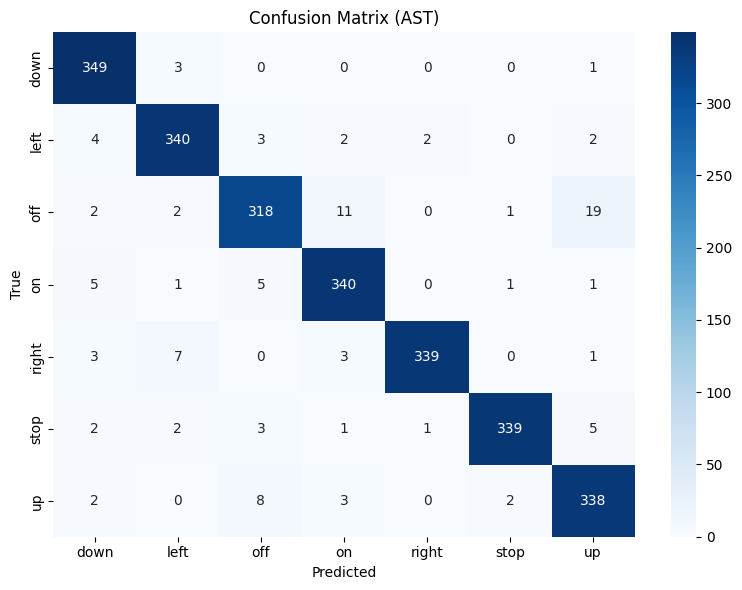

In [7]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (AST)")
plt.tight_layout()
plt.show()